**PREDICTING HOUSE PRICES IN AMES WITH MACHINE LEARNING**

I trained and compared several models on the Ames housing data, using the same 80/20 train/test split throughout, and studied where the best mdoel goes wrong

**SETUP AND ALL MODELS**

In [4]:
import numpy as np
import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.dummy import DummyRegressor
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor
from sklearn.metrics import mean_absolute_error, r2_score

df = pd.read_csv("train.csv")

no_feature_cols = ["PoolQC", "MiscFeature", "Alley", "Fence", "FireplaceQu",
                   "GarageType", "GarageFinish", "GarageQual", "GarageCond",
                   "BsmtQual", "BsmtCond", "BsmtExposure", "BsmtFinType1", "BsmtFinType2",
                   "MasVnrType"]
df[no_feature_cols] = df[no_feature_cols].fillna("None")
df["MasVnrArea"] = df["MasVnrArea"].fillna(0)
df["GarageYrBlt"] = df["GarageYrBlt"].fillna(0)
df["Electrical"] = df["Electrical"].fillna(df["Electrical"].mode()[0])

train, test = train_test_split(df, test_size=0.2, random_state=42)
train = train.copy()
test = test.copy()
median_frontage = train["LotFrontage"].median()
train["LotFrontage"] = train["LotFrontage"].fillna(median_frontage)
test["LotFrontage"] = test["LotFrontage"].fillna(median_frontage)

y_train = train["SalePrice"]
y_test = test["SalePrice"]

X_train_all = pd.get_dummies(train.drop(columns=["SalePrice", "Id"]), dtype=int)
X_test_all = pd.get_dummies(test.drop(columns=["SalePrice", "Id"]), dtype=int)
X_test_all = X_test_all.reindex(columns=X_train_all.columns, fill_value=0)

base_cols = ["GrLivArea", "OverallQual", "GarageCars", "YearBuilt", "TotalBsmtSF"]
hood_tr = pd.get_dummies(train["Neighborhood"], prefix="Hood", dtype=int)
hood_te = pd.get_dummies(test["Neighborhood"], prefix="Hood", dtype=int)
hood_te = hood_te.reindex(columns=hood_tr.columns, fill_value=0)

no_pool = [c for c in X_train_all.columns if c != "PoolArea" and not c.startswith("PoolQC")]

models = {
    "Baseline (guess the average)": (DummyRegressor(strategy="mean"), train[["GrLivArea"]], test[["GrLivArea"]]),
    "Linear: living area only": (LinearRegression(), train[["GrLivArea"]], test[["GrLivArea"]]),
     "Linear: five numeric features": (LinearRegression(), train[base_cols], test[base_cols]),
     "Linear: five features + neighborhood": (LinearRegression(),
          pd.concat([train[base_cols], hood_tr], axis=1), pd.concat([test[base_cols], hood_te], axis=1)),
      "Linear: all columns without pool": (LinearRegression(), X_train_all[no_pool], X_test_all[no_pool]),
      "Random forest": (RandomForestRegressor(n_estimators=300, random_state=42, n_jobs=-1), X_train_all, X_test_all),
      "Gradient boosting": (GradientBoostingRegressor(n_estimators=300, learning_rate=0.05, max_depth=3, random_state=42), X_train_all, X_test_all),
}

rows = []
fitted = {}
for name, (m, Xtr, Xte) in models.items():
  m.fit(Xtr, y_train)
  p = m.predict(Xte)
  fitted[name] = (m, Xte)
  rows.append({"Model": name,
               "MAE": round(mean_absolute_error(y_test, p)),
               "R2": round(r2_score(y_test, p), 2)})

results = pd.DataFrame(rows)
baseline_mae = results.loc[0, "MAE"]
results["Error vs baseline"] = ((1 - results["MAE"] / baseline_mae) * 100).round().astype(int).astype(str) + "% lower"
results.loc[0, "Error vs baseline"] = "-"
results




,Model,MAE,R2,Error vs baseline
0,Baseline (guess the average),62576,-0.00,-
1,Linear: living area only,38341,0.55,39% lower
2,Linear: five numeric features,25415,0.79,59% lower
3,Linear: five features + neighborhood,22339,0.83,64% lower
4,Linear: all columns without pool,19245,0.88,69% lower
5,Random forest,17426,0.89,72% lower
6,Gradient boosting,16626,0.90,73% lower


**RESULTS**

Every model was trained on 1,168 houses and tested on 292 houses it had never seen. The baseline always guesses the average price (error about 62,600). Living area alone cuts the error to about 38,300, five numeric features to about 25,400, and the best model, gradient boosting, to about 16,600 (R² 0.90), 73% lower than the baseline. The biggest single improvement came from adding overall quality, not from choosing a fancier algorithm.

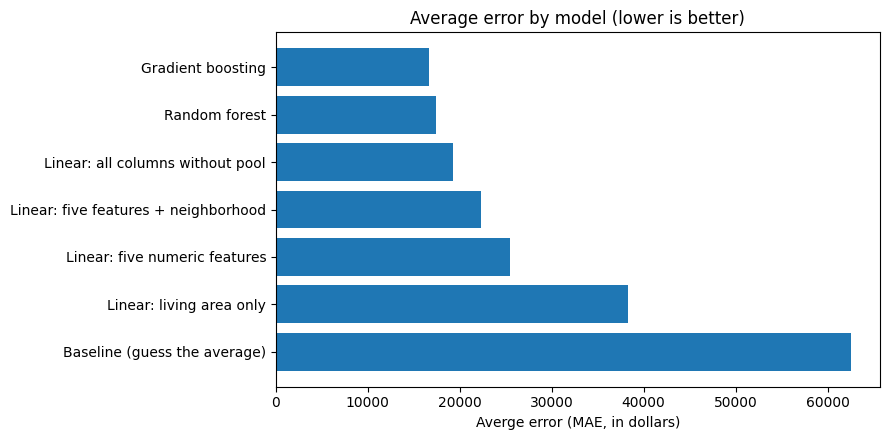

In [5]:
import matplotlib.pyplot as plt

plot = results.sort_values("MAE", ascending=False)
plt.figure(figsize=(9, 4.5))
plt.barh(plot["Model"], plot["MAE"])
plt.title("Average error by model (lower is better)")
plt.xlabel("Averge error (MAE, in dollars)")
plt.tight_layout()
plt.show()

**WHERE THE BEST MODEL FAILS**

The model’s median miss is about 10,400, and 69% of test houses are predicted within 10% of the real price (90% within 20%). Errors are concentrated: the worst 10 of 292 houses cause 57% of the squared error. All seven test houses over 400,000 were underpredicted, so the model tends to pull the most expensive houses toward the middle. Sale type also matters: the average miss is about 13,400 for Normal sales but about 42,400 for Partial sales (unfinished new construction).

**LIMITS**

All results come from one train/test split, so small differences between models are not firm. The pool columns were dropped from the linear model after I saw it fail on one test house, so that score is slightly optimistic. Feature importance shows what the model uses, not what causes prices. The data covers one town (Ames, Iowa), so the model would need retraining for another market.

**SUMMARY**

I compared seven ways of predicting house prices in Ames, Iowa, from a baseline that always guesses the average (average error about 62,600) to gradient boosting (about 16,600, R² 0.90), which is 73% lower. The biggest improvement came from giving the model the right information, mainly overall quality, and not from switching to a fancier algorithm. The model works well on typical houses, with 69% of predictions within 10% of the real price, but it tends to underpredict the most expensive houses and struggles with unfinished new construction. Next, I will turn the best model into a small app that predicts a price from a few inputs.